# Computer simulations of a coffee berry borer infestation model

## Import necessary libraries

In [1]:
import sys  
sys.path.insert(0, '../pyscripts/')
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from models_cls import *

## Model parameters
Read and show the values of the model parameters.

In [2]:
switch = False # use reproduction rate constant (False) or variable (True)
phi = 80 # coffee harvest percentage
b0 = 0 # initial amount of CBBs
mu = 0 # number of CBBs coming from outside in each seasson after the 1st (CBB/tree)
if switch:
    data_file = Path('..') / 'data' / 'params_varrepro.csv'
else:
    data_file = Path('..') / 'data' / 'params_constrepro.csv'
initiate_simulations = initiate(switch, phi, b0, mu, data_file)
parameters = initiate_simulations.parameter_values()
print('Model parameters:')
pd.set_option('display.max_colwidth', None)
display(initiate_simulations.df) # show the parameters in a table

Model parameters:


,Value,Description
Parameter,,
coffee_total,1000.0,total number of coffee berries in the season (berry/tree)
kappa_b_berry,20.0,CBB carrying capacity per berry (CBB/berry)
rho_b,0.0345,CBB reproduction rate (1/day) at 24 C Jaramillo et al 2009
epsbe2rhob,0.75,"ratio of exiting to reproduction rate (0, 1)"
del_b,0.001,free-borer death rate (1/day) Romero and Cortina 2007
cu0,1.0,value to scale the total number of coffee berries
t0,0.0,season starting time (day)
th,184.0,harvesting time (day)
tf,364.0,season ending time (day)


## One-dimensional map 
Compute fixed points of the one-dimensional map and classify them as stable or unstable.

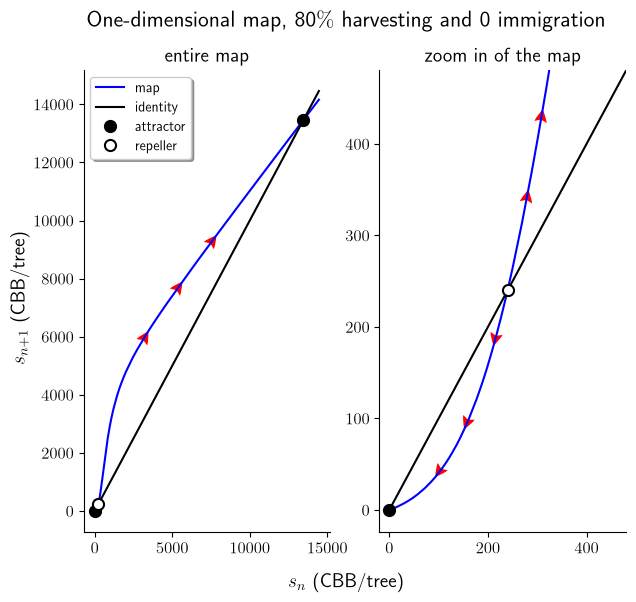

 
Percentage of coffee harvested: 80%
CBBs coming from outside in each season after the 1st: 0 CBB/tree
Using constant reproduction rate
 
Results of the map:
first attractor: 0 CBB/tree
threshold: 240 CBB/tree
second attractor: 13461 CBB/tree
-------------------------------------------------------
attractor: attracting or stable fixed point
threshold: repelling or unstable fixed point
Note:
For any value of initial free CBB/tree in the interval
[0, 240) the amount of free CBB at the start of subsequent seasons
decreases to 0 CBB/tree if one maintains at least 80% of harvesting.
Whereas for any value of initial free CBB/tree in the interval
(240, 13461] the amount of free CBB at the start of subsequent seasons
increases to 13461 CBB/tree if one maintains at least 80% of harvesting.
 
Execution time of the map: 2.297193949166649 min
 


In [3]:
map_max_itr = 1E5
parameters = reset(parameters, b0=0, delta_bo=1, max_itr=map_max_itr) # reset or add parameters
map_simulation = map_1d(parameters)
g, bo_array, stable_pts, unstable_pts, et = map_simulation.solve()

_, ax = map_simulation.plotting(g, bo_array, stable_pts, unstable_pts)
plt.show()
print(' ')
map_simulation.printing(g, bo_array, stable_pts, unstable_pts, et)

## Model simulation
Compute model simulations for a single season whenever the map exhibits two stable fixed points with one unstable fixed point in between. The unstable fixed point being a threshold.

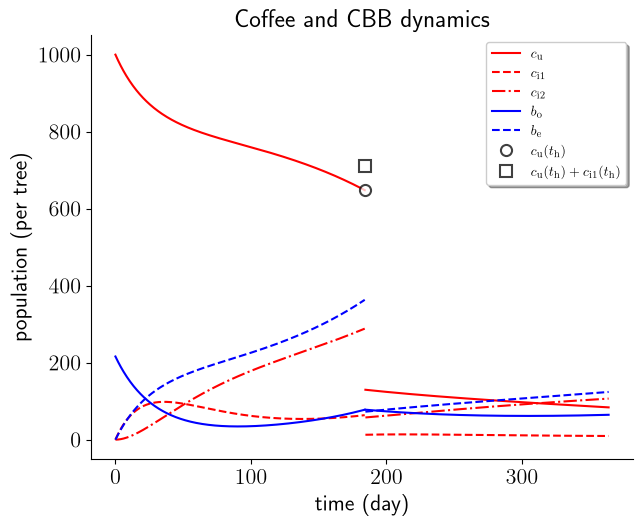

 
Results of the model for a coffee season:
Percentage of consumable coffee at harvest: 71%
Percentage of consumable coffee at the end of the season: 9%
Amount of CBB at the beginning of the season: 216 CBB/tree
Amount of CBB at the end of the season: 188 CBB/tree
 


In [4]:
if unstable_pts.size > 0:
    b0 = round(0.9*unstable_pts[0]) # initial amount of CBB/tree
    parameters = reset(parameters, b0=b0)
    model_simulation = model(parameters)
    sol_bef, sol_aft = model_simulation.solve()
    _, ax = model_simulation.plotting(sol_bef, sol_aft)
    plt.show()
    print(' ')
    model_simulation.printing(sol_bef, sol_aft)
else:
    print('Because there is only one stable fixed point '
          'that leads to\ntotal infestation, we do not show '
          'model simulations.')

## Multiseason simulation
Compute model simulations for multiple seasons whenever the map exhibits a threshold in between two atractors.

Results of multiple coffee seasons:
Initial amount of CBBs: 216
CBBs at the end of season 7: 0 CBB/tree 
 


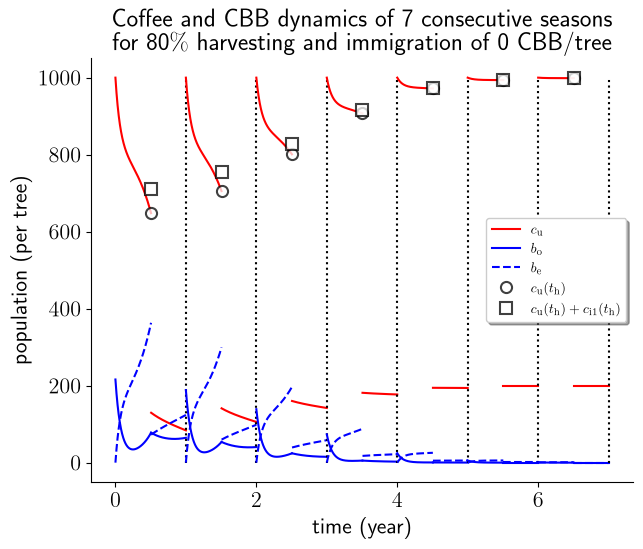

In [5]:
if unstable_pts.size > 0:
    parameters = reset(parameters, stable_1=stable_pts[0], ny_max=50)
    multi_simulation = multiseason(parameters)
    _, ax = multi_simulation.outputs()
    plt.show()
else:
    print('Because there is only one stable fixed point '
          'that leads to\ntotal infestation, we do not show '
          'model simulations.')

## Bifurcation diagram
Using the one-dimesional map to compute fixed points of the map and classify then as stable or unstable for different values of harvesting percentage (phi). Computation is done in parallel.

CBBs coming from outside: 0 CBB/tree
Using constant reproduction rate
 


,First attractor,Threshold,Second attractor
Harvesting(%),,,
100,0,412,10613
90,0,338,11647
80,0,240,13461
70,0,173,16124
60,0,125,19714
50,0,91,24310
40,0,65,29974
30,0,44,36775
20,0,28,44773


 
attractor (CBB/tree): attracting or stable fixed point
threshold (CBB/tree): repelling or unstable fixed point
Note:
1) To be able to control the infestation of CBB choose a percentage
of harvesting such that the initial free CBB/tree in the first
season is less than the corresponding threshold.
2) Graph scale on the vertical axis is split: lower values 0 to 500
correspond to the threshold and first attractor branch; higher
values 1 to 7 ×10^4 correspond to the second attractor branch.
 
Execution time of the bifurcation diagram: 33.0433227711 min
Using 8 CPU cores in parallel
 


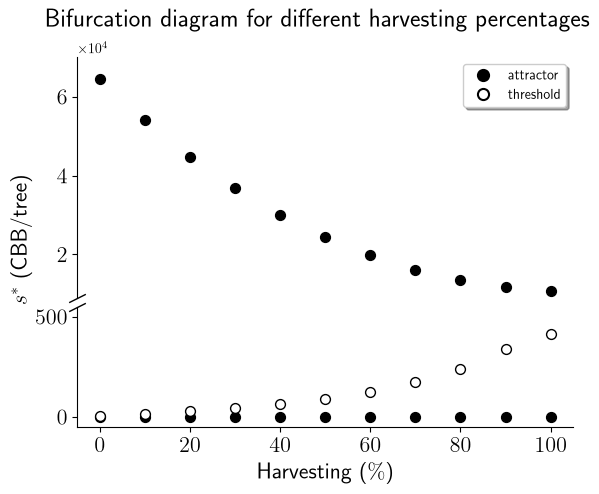

In [6]:
import numpy as np
import time
import os
from multiprocessing import Pool
from functools import partial

process_nums = os.cpu_count() # number of cores available in the system
phi_array = np.arange(100, -10, -10)/100 # variation of percentage of coffee harvest
parameters = reset(parameters, b0=0, delta_bo=1, max_itr=map_max_itr)
b_diagram = bpoints(parameters)

if __name__ == "__main__":
    """
    Computation done in parallel for different values of harvesting
    percentage (phi)
    """
    st = time.perf_counter()
    stable_array = []
    unstable_array = []
    stable_lonely = []
    fixed_points = partial(b_diagram.solve, parameters=parameters)
    with Pool(processes=process_nums, maxtasksperchild=1) as pool:
        results = pool.map(fixed_points, phi_array)
        for arr in results:
            if len(arr[0]) == 2:
               stable_array.append(arr[0][:])
               unstable_array.append(arr[1][:])
            else:
               stable_lonely.append(arr[0][:])
    stable_array = np.array(stable_array)
    unstable_array = np.array(unstable_array)
    stable_lonely = np.array(stable_lonely)
    et = (time.perf_counter() - st)

    _, (ax1, ax2) = b_diagram.outputs(phi_array, stable_array,
                                      unstable_array, stable_lonely, et, process_nums)
    plt.show()